# 04 · KHAI PHÁ TẬP MỤC PHỔ BIẾN VÀ LUẬT KẾT HỢP

## 0. Thiết lập môi trường và nạp dữ liệu

In [6]:
# 0.1. Cài thư viện cần thiết (chỉ cài nếu thiếu)
import sys, subprocess, importlib.util
packages = {"duckdb": "duckdb", "mlxtend": "mlxtend", "pyarrow": "pyarrow",
            "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Đang cài:", missing, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Đã có đủ các thư viện cần thiết.")
print("B4 - THIET LAP THU VIEN: DAT")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Đã có đủ các thư viện cần thiết.
B4 - THIET LAP THU VIEN: DAT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
# AN CANH BAO DEPRECATIONWARNING TU JUPYTER_CLIENT

import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning
)

print("DA BAT BO LOC CANH BAO DEPRECATIONWARNING")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

DA BAT BO LOC CANH BAO DEPRECATIONWARNING


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
# 0.2. Đường dẫn, tham số và kết nối dữ liệu
import os, sys, time, json
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from mlxtend.frequent_patterns import apriori, fpgrowth
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# Thư mục gốc của repo, dùng chung cho cả năm notebook
REPO_DIR = Path(os.environ.get("REPO_DIR", "/content/drive/MyDrive/Nhom04_ADM/repo" if IN_COLAB else ".."))
SOURCE_DB = REPO_DIR / "data" / "processed" / "step3_transactions_for_association_mining.duckdb"  # do notebook 03 tạo
INPUT_DIR = REPO_DIR / "outputs" / "step4"            # kết quả gốc đã dùng trong báo cáo, để đối chiếu ở mục 6
OUTPUT_DIR = REPO_DIR / "outputs" / "step4_chay_lai"  # kết quả lần chạy này, không ghi đè bản gốc
TEST_DIR = OUTPUT_DIR / "Test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TEST_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_TEST = 5000
N_MAIN = 10000
SUPPORT_LEVELS_TEST = [0.02, 0.05, 0.10]
TEST_REPEATS = 3
MIN_SUPPORT_MAIN = 0.10
MAX_LEN = 3
MIN_CONFIDENCE = 0.50
MIN_LIFT_EXCLUSIVE = 1.0

if not SOURCE_DB.is_file():
    raise FileNotFoundError(f"Không thấy {SOURCE_DB}. Hãy chạy notebook 03 trước.")
with duckdb.connect(str(SOURCE_DB), read_only=True) as _check_con:
    _found = {r[0] for r in _check_con.execute("SHOW TABLES").fetchall()}
_required = {"transactions_aisle", "transactions_department"}
if not _required.issubset(_found):
    raise ValueError(f"DuckDB {SOURCE_DB} thiếu các bảng: {_required - _found}")

print("SOURCE DB:", SOURCE_DB)
print("SOURCE TABLES:", sorted(_found))
print("REFERENCE DIR:", INPUT_DIR)
print("OUTPUT DIR:", OUTPUT_DIR)
print("Cấu hình:", {"seed": SEED, "test": N_TEST, "main": N_MAIN,
       "support_main": MIN_SUPPORT_MAIN, "max_len": MAX_LEN,
       "confidence": MIN_CONFIDENCE, "lift>": MIN_LIFT_EXCLUSIVE})
print("B4 - KET NOI DU LIEU: DAT")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SOURCE DB: /content/drive/MyDrive/Nhom04_ADM/repo/data/processed/step3_transactions_for_association_mining.duckdb
SOURCE TABLES: ['dim_order', 'dim_product', 'dim_user', 'fact_order_product', 'transactions_aisle', 'transactions_department']
REFERENCE DIR: /content/drive/MyDrive/Nhom04_ADM/repo/outputs/step4
OUTPUT DIR: /content/drive/MyDrive/Nhom04_ADM/repo/outputs/step4_chay_lai
Cấu hình: {'seed': 42, 'test': 5000, 'main': 10000, 'support_main': 0.1, 'max_len': 3, 'confidence': 0.5, 'lift>': 1.0}
B4 - KET NOI DU LIEU: DAT


## T29 · Kiểm tra và mã hóa giao dịch ở hai mức phân cấp
Mỗi đơn hàng `order_id` là **một giao dịch**. Những mã aisle/department trùng lặp trong cùng đơn chỉ được tính một lần khi chuyển sang ma trận nhị phân. Hai ma trận phải có tập `order_id` như nhau. Tổng quy mô dự kiến theo dữ liệu B3 là 206.657 đơn, 134 aisle và 21 department.

In [9]:
# T29.1 - Đọc DuckDB, kiểm tra khóa, giỏ rỗng, mã nhóm và tính nhất quán
con = duckdb.connect(str(SOURCE_DB), read_only=True)
actual_tables = {row[0] for row in con.execute("SHOW TABLES").fetchall()}
required_tables = {"transactions_aisle", "transactions_department"}
assert required_tables <= actual_tables, f"Thiếu bảng: {required_tables - actual_tables}"

def load_transactions(table, list_column, max_id):
    rows = con.execute(f"SELECT order_id, {list_column} FROM {table} ORDER BY order_id").fetchall()
    ids, baskets = [], []
    missing_id = empty_count = repeated_item_count = 0
    for order_id, items in rows:
        if order_id is None:
            missing_id += 1
            continue
        ids.append(int(order_id))
        items = list(items or [])
        if not items:
            empty_count += 1
        if len(items) != len(set(items)):
            repeated_item_count += 1
        if any(item is None or not 1 <= int(item) <= max_id for item in items):
            raise ValueError(f"{table}: mã nhóm hàng ngoài miền hợp lệ tại order_id={order_id}")
        baskets.append(sorted(set(int(x) for x in items)))
    if missing_id:
        raise ValueError(f"{table}: có {missing_id} order_id thiếu")
    if len(ids) != len(set(ids)):
        raise ValueError(f"{table}: có order_id trùng")
    if empty_count:
        raise ValueError(f"{table}: có {empty_count} giỏ hàng rỗng")
    return ids, baskets, repeated_item_count

ids_a, baskets_a, dup_items_a = load_transactions("transactions_aisle", "aisle_items", 134)
ids_d, baskets_d, dup_items_d = load_transactions("transactions_department", "department_items", 21)
con.close()
assert ids_a == ids_d, "Hai cấp không có cùng danh sách order_id"

quality = pd.DataFrame([
    dict(bang="transactions_aisle", so_giao_dich=len(ids_a), so_order_id=len(set(ids_a)),
         ma_don_bi_thieu=0, don_bi_trung=0, gio_hang_rong=0,
         gio_co_nhom_lap=dup_items_a, order_id_khong_co_o_bang_kia=0),
    dict(bang="transactions_department", so_giao_dich=len(ids_d), so_order_id=len(set(ids_d)),
         ma_don_bi_thieu=0, don_bi_trung=0, gio_hang_rong=0,
         gio_co_nhom_lap=dup_items_d, order_id_khong_co_o_bang_kia=0)
])
quality.to_csv(OUTPUT_DIR / "T29_transaction_quality.csv", index=False, encoding="utf-8-sig")
display(quality)
print("T29.1 - KIEM TRA CHAT LUONG: DAT")

,bang,so_giao_dich,so_order_id,ma_don_bi_thieu,don_bi_trung,gio_hang_rong,gio_co_nhom_lap,order_id_khong_co_o_bang_kia
0,transactions_aisle,206657,206657,0,0,0,0,0
1,transactions_department,206657,206657,0,0,0,0,0


T29.1 - KIEM TRA CHAT LUONG: DAT


In [10]:
# T29.2 - Tạo ma trận giao dịch nhị phân, lưu Parquet

def encode_transactions(ids, baskets, prefix, n_groups):
    data = np.zeros((len(ids), n_groups), dtype=np.uint8)
    for i, basket in enumerate(baskets):
        if basket:
            data[i, np.asarray(basket, dtype=int) - 1] = 1
    X = pd.DataFrame(data, index=pd.Index(ids, name="order_id"),
                     columns=[f"{prefix}_{j}" for j in range(1, n_groups + 1)])
    assert not X.index.has_duplicates
    assert X.isin([0, 1]).all().all()
    return X

matrix_aisle = encode_transactions(ids_a, baskets_a, "aisle", 134)
matrix_department = encode_transactions(ids_d, baskets_d, "department", 21)
assert matrix_aisle.index.equals(matrix_department.index)
assert matrix_aisle.shape[0] == 206657, "Số đơn khác đầu vào B3 đã báo cáo"

matrix_aisle.to_parquet(OUTPUT_DIR / "T29_matrix_aisle.parquet", index=True)
matrix_department.to_parquet(OUTPUT_DIR / "T29_matrix_department.parquet", index=True)
print("Aisle:", matrix_aisle.shape, "| Department:", matrix_department.shape)
print("T29.2 - MA HOA NHI PHAN: DAT")

Aisle: (206657, 134) | Department: (206657, 21)
T29.2 - MA HOA NHI PHAN: DAT


## T30 · Apriori và FP-Growth: phân tích ngưỡng Support, sau đó mở rộng 10.000 đơn
Hai thuật toán chạy trên **cùng ma trận** và cùng `max_len=3`; kiểm tra trùng khớp tập mục và Support. Giai đoạn A: 5.000 đơn ở Support 2%, 5%, 10%, lặp mỗi thuật toán 3 lần; Giai đoạn B: 10.000 đơn cùng ID ở hai cấp và Support 10%. Thời gian phụ thuộc phần cứng và không được dùng như một hằng số để kiểm chứng tái lập.

In [11]:
# T30.1 - Hàm khai phá, chuẩn hóa và so sánh kết quả

def run_miner(algorithm, X, min_support):
    t0 = time.perf_counter()
    result = algorithm(X, min_support=min_support, use_colnames=True, max_len=MAX_LEN)
    return result, time.perf_counter() - t0

def normalized_itemsets(df):
    return {frozenset(items): float(support)
            for support, items in df[["support", "itemsets"]].itertuples(index=False, name=None)}

def ensure_same_itemsets(a, b, atol=1e-10):
    da, db = normalized_itemsets(a), normalized_itemsets(b)
    assert da.keys() == db.keys(), "Apriori và FP-Growth không trùng danh sách tập mục"
    assert all(abs(da[k] - db[k]) < atol for k in da), "Support hai thuật toán không khớp"

def export_itemsets(df, path):
    out = df.copy()
    out["itemsets"] = out["itemsets"].map(lambda x: ", ".join(sorted(x)))
    out.to_csv(path, index=False, encoding="utf-8-sig")

print("T30.1 - CAC HAM DA SAN SANG")

T30.1 - CAC HAM DA SAN SANG


Đang kiểm tra Support 2%...
Support: 2% - tập mục: 739 - DOI CHIEU: DAT
Đang kiểm tra Support 5%...
Support: 5% - tập mục: 157 - DOI CHIEU: DAT
Đang kiểm tra Support 10%...
Support: 10% - tập mục: 36 - DOI CHIEU: DAT


,algorithm,transactions,min_support,max_len,repeats,frequent_itemsets,median_runtime_seconds,min_runtime_seconds,max_runtime_seconds
0,Apriori,5000,0.02,3,3,739,0.215148,0.200235,0.280225
1,FP-Growth,5000,0.02,3,3,739,14.611669,12.316432,14.635990
2,Apriori,5000,0.05,3,3,157,0.038054,0.037248,0.040303
3,FP-Growth,5000,0.05,3,3,157,1.685152,1.656995,1.964931
4,Apriori,5000,0.10,3,3,36,0.017842,0.009959,0.042256
5,FP-Growth,5000,0.10,3,3,36,1.344101,1.334081,1.898815


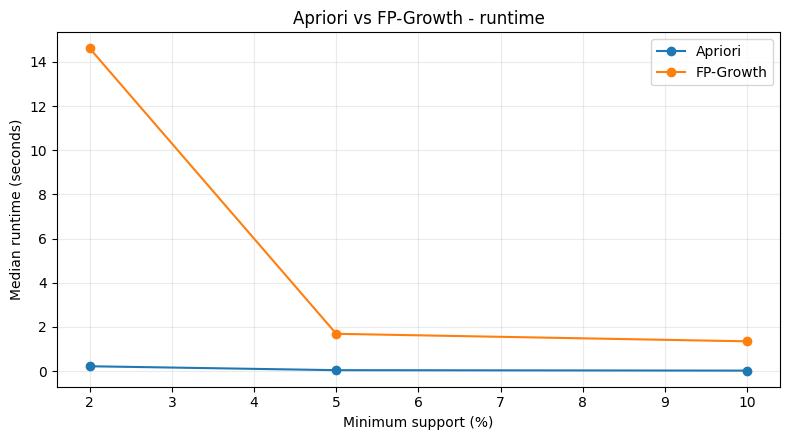

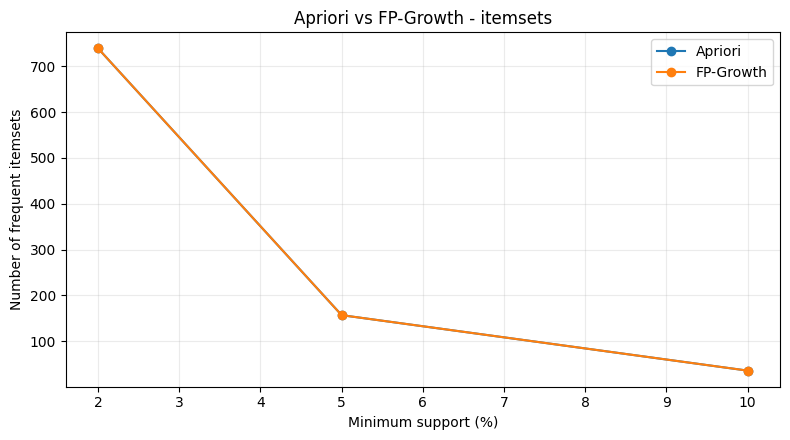

T30.2 - PHAN TICH SUPPORT: DAT


In [12]:
# T30.2 - 5.000 giao dịch Aisle, ba Support x hai thuật toán x ba lượt
X_test = matrix_aisle.sample(n=N_TEST, random_state=SEED).astype(bool)
records_test = []
for s in SUPPORT_LEVELS_TEST:
    print(f"Đang kiểm tra Support {s:.0%}...", flush=True)
    outputs = {}
    for algorithm_name, algorithm in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        durations = []
        for repeat in range(TEST_REPEATS):
            itemsets, elapsed = run_miner(algorithm, X_test, s)
            durations.append(elapsed)
            if repeat == 0:
                outputs[algorithm_name] = itemsets
        d = np.asarray(durations)
        records_test.append({
            "algorithm": algorithm_name, "transactions": N_TEST,
            "min_support": s, "max_len": MAX_LEN, "repeats": TEST_REPEATS,
            "frequent_itemsets": len(itemsets), "median_runtime_seconds": float(np.median(d)),
            "min_runtime_seconds": float(d.min()), "max_runtime_seconds": float(d.max())
        })
    ensure_same_itemsets(outputs["Apriori"], outputs["FP-Growth"])
    if s == 0.05:
        export_itemsets(outputs["Apriori"], TEST_DIR / "T30_apriori_aisle_test.csv")
        export_itemsets(outputs["FP-Growth"], TEST_DIR / "T30_fpgrowth_aisle_test.csv")
    print("Support:", f"{s:.0%}", "- tập mục:", len(outputs["Apriori"]), "- DOI CHIEU: DAT", flush=True)

test_summary = pd.DataFrame(records_test)
test_summary.to_csv(TEST_DIR / "T30_support_comparison_test.csv", index=False, encoding="utf-8-sig")
test_summary[test_summary.min_support == 0.05].to_csv(
    TEST_DIR / "T30_comparison_test.csv", index=False, encoding="utf-8-sig")
display(test_summary)

for col, ylabel, fname, title in [
    ("median_runtime_seconds", "Median runtime (seconds)", "T30_runtime_comparison_test.png", "Apriori vs FP-Growth - runtime"),
    ("frequent_itemsets", "Number of frequent itemsets", "T30_itemset_count_test.png", "Apriori vs FP-Growth - itemsets"),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for name in ["Apriori", "FP-Growth"]:
        subset = test_summary[test_summary.algorithm == name].sort_values("min_support")
        ax.plot(subset.min_support * 100, subset[col], marker="o", label=name)
    ax.set(xlabel="Minimum support (%)", ylabel=ylabel, title=title)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(TEST_DIR / fname, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("T30.2 - PHAN TICH SUPPORT: DAT")

Đang chạy aisle / Apriori...
Apriori: 36 tập mục, 0.0216 giây
Đang chạy aisle / FP-Growth...
FP-Growth: 36 tập mục, 0.7020 giây
Đang chạy department / Apriori...
Apriori: 93 tập mục, 0.0130 giây
Đang chạy department / FP-Growth...
FP-Growth: 93 tập mục, 2.3322 giây


,level,algorithm,transactions,min_support,frequent_itemsets,runtime_seconds
0,aisle,Apriori,10000,0.1,36,0.021592
1,aisle,FP-Growth,10000,0.1,36,0.702026
2,department,Apriori,10000,0.1,93,0.012977
3,department,FP-Growth,10000,0.1,93,2.332244


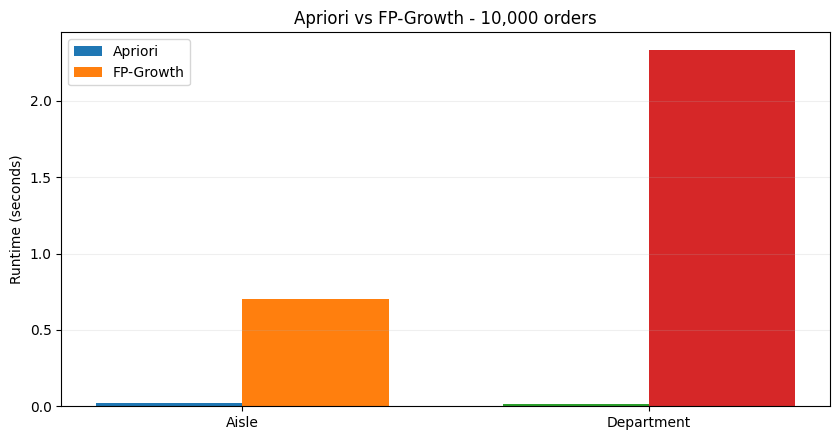

T30.3 - THUC NGHIEM CHINH: DAT


In [13]:
# T30.3 - 10.000 ID giống nhau cho Aisle và Department, Support 10%
sample_ids = matrix_aisle.sample(n=N_MAIN, random_state=SEED).index
X_main = {
    "aisle": matrix_aisle.loc[sample_ids].astype(bool),
    "department": matrix_department.loc[sample_ids].astype(bool),
}
assert X_main["aisle"].index.equals(X_main["department"].index)
pd.DataFrame({"order_id": sample_ids}).to_csv(
    OUTPUT_DIR / "T30_sample_order_ids.csv", index=False, encoding="utf-8-sig")

main_itemsets = {}
main_stats = []
for level, X in X_main.items():
    outputs = {}
    for name, algorithm in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        print(f"Đang chạy {level} / {name}...", flush=True)
        frequent, elapsed = run_miner(algorithm, X, MIN_SUPPORT_MAIN)
        outputs[name] = frequent
        main_stats.append({"level": level, "algorithm": name, "transactions": len(X),
                           "min_support": MIN_SUPPORT_MAIN, "frequent_itemsets": len(frequent),
                           "runtime_seconds": elapsed})
        print(f"{name}: {len(frequent)} tập mục, {elapsed:.4f} giây", flush=True)
    ensure_same_itemsets(outputs["Apriori"], outputs["FP-Growth"])
    main_itemsets[level] = outputs["FP-Growth"]
    export_itemsets(main_itemsets[level], OUTPUT_DIR / f"T30_{level}_frequent_itemsets.csv")

main_summary = pd.DataFrame(main_stats)
main_summary.to_csv(OUTPUT_DIR / "T30_comparison.csv", index=False, encoding="utf-8-sig")
display(main_summary)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, level in enumerate(["aisle", "department"]):
    part = main_summary[main_summary.level == level].set_index("algorithm")
    ax.bar(i - 0.18, part.loc["Apriori", "runtime_seconds"], width=0.36, label="Apriori" if i == 0 else "")
    ax.bar(i + 0.18, part.loc["FP-Growth", "runtime_seconds"], width=0.36, label="FP-Growth" if i == 0 else "")
ax.set_xticks([0, 1], ["Aisle", "Department"])
ax.set(ylabel="Runtime (seconds)", title="Apriori vs FP-Growth - 10,000 orders")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "T30_performance_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("T30.3 - THUC NGHIEM CHINH: DAT")

## T31 · Kiểm tra tập mục phổ biến đóng
Đây là **hậu lọc tập mục đã khai phá** (không phải triển khai đầy đủ thuật toán CHARM). Với từng tập mục từ T30 (`max_len=3`), kiểm tra trên chính 10.000 giao dịch xem có mục khác cùng xuất hiện trong **mọi** giao dịch chứa tập đó hay không. Nếu có thì tập ban đầu không đóng; cách kiểm tra này xét cả khả năng phần mở rộng dài hơn 3.

,level,transactions,min_support,max_len_mined,frequent_itemsets,closed_itemsets,closed_ratio,reduction_count,reduction_percent
0,aisle,10000,0.1,3,36,36,1.0,0,0.0
1,department,10000,0.1,3,93,93,1.0,0,0.0


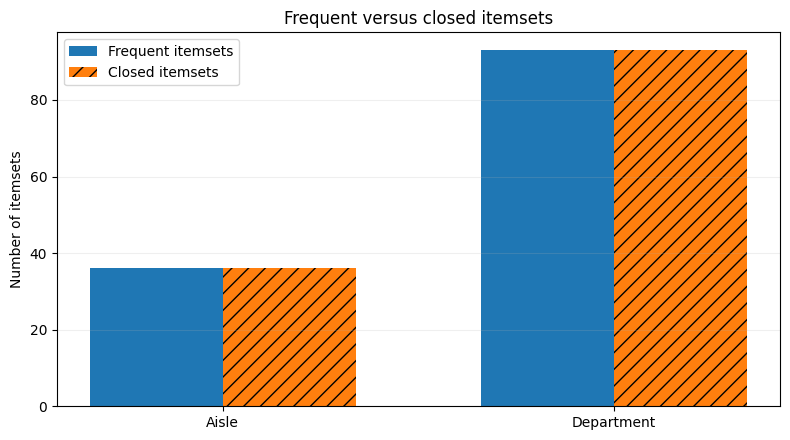

T31 - KIEM TRA TAP DONG: DAT


In [14]:
# T31.1 - Kiểm tra tính đóng từ ma trận giao dịch
closed_stats = []
closed_checks = {}
for level, X in X_main.items():
    A = X.to_numpy(dtype=bool)
    names = list(X.columns)
    positions = {name: i for i, name in enumerate(names)}
    frequent = main_itemsets[level]
    records = []
    for support, itemset in frequent[["support", "itemsets"]].itertuples(index=False, name=None):
        items = sorted(itemset)
        idx = [positions[x] for x in items]
        covered = np.all(A[:, idx], axis=1)
        count = int(covered.sum())
        computed = count / len(A)
        assert abs(computed - float(support)) < 1e-10, "Sai lệch Support T30/T31"
        common = np.all(A[covered], axis=0)
        extra = [names[j] for j in np.flatnonzero(common) if j not in idx]
        records.append({"support": computed, "itemsets": ", ".join(items),
                        "itemset_length": len(items), "matching_transactions": count,
                        "is_closed": not bool(extra), "equal_support_extensions": ", ".join(extra)})
    checks = pd.DataFrame(records)
    closed = checks[checks.is_closed].copy()
    closed_checks[level] = checks
    checks.to_csv(OUTPUT_DIR / f"T31_closed_check_{level}.csv", index=False, encoding="utf-8-sig")
    closed.to_csv(OUTPUT_DIR / f"T31_closed_{level}.csv", index=False, encoding="utf-8-sig")
    closed_stats.append({"level": level, "transactions": len(X), "min_support": MIN_SUPPORT_MAIN,
                         "max_len_mined": MAX_LEN, "frequent_itemsets": len(checks),
                         "closed_itemsets": len(closed), "closed_ratio": len(closed) / len(checks)})

closed_summary = pd.DataFrame(closed_stats)
closed_summary.to_csv(OUTPUT_DIR / "T31_closed_summary.csv", index=False, encoding="utf-8-sig")
reduction = closed_summary.copy()
reduction["reduction_count"] = reduction.frequent_itemsets - reduction.closed_itemsets
reduction["reduction_percent"] = 100 * reduction.reduction_count / reduction.frequent_itemsets
reduction.to_csv(OUTPUT_DIR / "T31_closed_reduction.csv", index=False, encoding="utf-8-sig")
display(reduction)
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(closed_summary))
ax.bar(x-0.17, closed_summary.frequent_itemsets, width=0.34, label="Frequent itemsets")
ax.bar(x+0.17, closed_summary.closed_itemsets, width=0.34,
       label="Closed itemsets", hatch="//")
ax.set_xticks(x, ["Aisle", "Department"])
ax.set(ylabel="Number of itemsets", title="Frequent versus closed itemsets")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "T31_closed_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("T31 - KIEM TRA TAP DONG: DAT")

## T32 · Sinh luật kết hợp và phân tích độ nhạy
Sinh luật từ **toàn bộ tập mục phổ biến T30**, không chỉ tập đóng T31. Công thức sử dụng: `confidence(X→Y)=support(X∪Y)/support(X)`; `lift(X→Y)=confidence(X→Y)/support(Y)`. Giữ ngưỡng Support 10%, Confidence ≥50%, Lift >1; khảo sát Confidence 30–80% và Lift 1,0–1,4.

In [15]:
# T32.1 - Sinh luật theo toàn bộ tập mục, tính ba chỉ số

def build_rules(frequent):
    support = normalized_itemsets(frequent)
    rules = []
    for itemset, support_xy in support.items():
        if len(itemset) < 2:
            continue
        items = sorted(itemset)
        for k in range(1, len(items)):
            for combo in combinations(items, k):
                X = frozenset(combo)
                Y = itemset - X
                if X not in support or Y not in support:
                    raise ValueError(f"Thiếu Support tập con của {items}")
                support_x, support_y = support[X], support[Y]
                confidence = support_xy / support_x
                rules.append({"antecedents": ", ".join(sorted(X)),
                              "consequents": ", ".join(sorted(Y)),
                              "support": support_xy, "antecedent_support": support_x,
                              "consequent_support": support_y, "confidence": confidence,
                              "lift": confidence / support_y, "rule_length": len(itemset)})
    columns = ["antecedents", "consequents", "support", "antecedent_support",
               "consequent_support", "confidence", "lift", "rule_length"]
    return pd.DataFrame(rules, columns=columns).sort_values(
        ["lift", "confidence"], ascending=[False, False]).reset_index(drop=True)

all_rules = {}
filtered_rules = {}
rules_stats = []
for level in ["aisle", "department"]:
    df = build_rules(main_itemsets[level])
    selected = df[(df.confidence >= MIN_CONFIDENCE) & (df.lift > MIN_LIFT_EXCLUSIVE)].copy()
    all_rules[level] = df
    filtered_rules[level] = selected
    df.to_csv(OUTPUT_DIR / f"T32_all_rules_{level}.csv", index=False, encoding="utf-8-sig")
    selected.to_csv(OUTPUT_DIR / f"T32_filtered_rules_{level}.csv", index=False, encoding="utf-8-sig")
    rules_stats.append({"level": level, "transactions": N_MAIN, "min_support": MIN_SUPPORT_MAIN,
                        "min_confidence": MIN_CONFIDENCE, "min_lift_exclusive": MIN_LIFT_EXCLUSIVE,
                        "all_rules": len(df), "filtered_rules": len(selected),
                        "filtered_ratio": len(selected)/len(df) if len(df) else 0})

rules_summary = pd.DataFrame(rules_stats)
rules_summary.to_csv(OUTPUT_DIR / "T32_rules_summary.csv", index=False, encoding="utf-8-sig")
display(rules_summary)
print("T32.1 - SINH LUAT: DAT")

,level,transactions,min_support,min_confidence,min_lift_exclusive,all_rules,filtered_rules,filtered_ratio
0,aisle,10000,0.1,0.5,1.0,56,26,0.464286
1,department,10000,0.1,0.5,1.0,310,112,0.361290


T32.1 - SINH LUAT: DAT


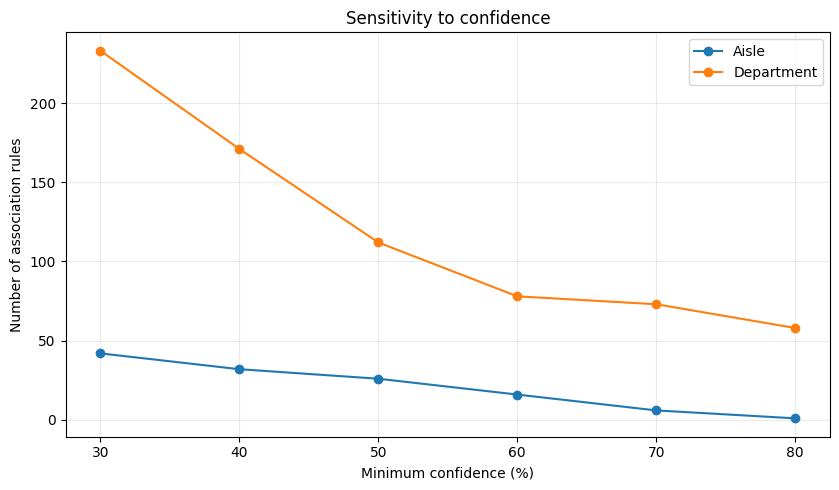

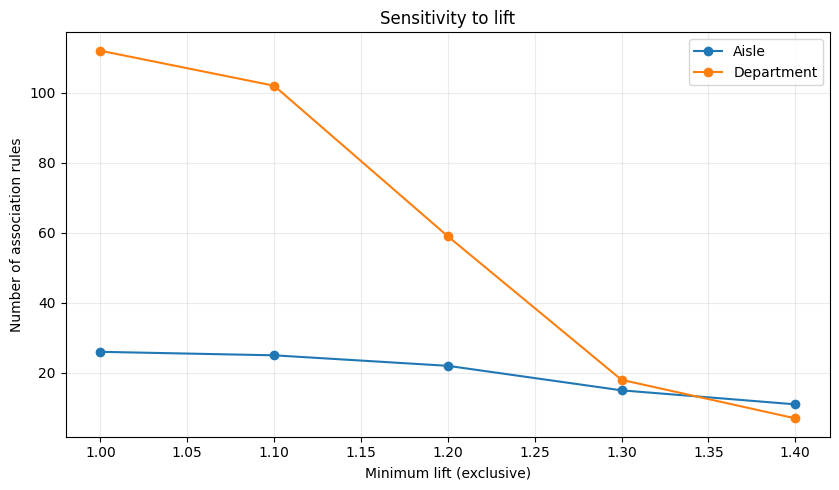

,level,min_confidence,selected_rules
0,aisle,0.3,42
5,aisle,0.4,32
10,aisle,0.5,26
15,aisle,0.6,16
20,aisle,0.7,6
25,aisle,0.8,1
30,department,0.3,233
35,department,0.4,171
40,department,0.5,112
45,department,0.6,78


T32.2 - PHAN TICH DO NHAY: DAT


In [16]:
# T32.2 - Độ nhạy Confidence và Lift trên các luật đã sinh
confidence_levels = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
lift_levels = [1.0, 1.1, 1.2, 1.3, 1.4]
sensitivity_rows = []
for level, df in all_rules.items():
    for confidence in confidence_levels:
        for lift in lift_levels:
            n = int(((df.confidence >= confidence) & (df.lift > lift)).sum())
            sensitivity_rows.append({"level": level, "min_support": MIN_SUPPORT_MAIN,
                                     "min_confidence": confidence, "min_lift_exclusive": lift,
                                     "total_rules": len(df), "selected_rules": n,
                                     "retention_ratio": n / len(df) if len(df) else 0})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUTPUT_DIR / "T32_threshold_sensitivity.csv", index=False, encoding="utf-8-sig")
assert len(sensitivity) == 60
for variable, fixed, column, xs, xlabel, title, filename in [
    ("min_confidence", ("min_lift_exclusive", 1.0), "selected_rules", confidence_levels,
     "Minimum confidence (%)", "Sensitivity to confidence", "T32_confidence_sensitivity.png"),
    ("min_lift_exclusive", ("min_confidence", 0.50), "selected_rules", lift_levels,
     "Minimum lift (exclusive)", "Sensitivity to lift", "T32_lift_sensitivity.png")
]:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    for level in ["aisle", "department"]:
        d = sensitivity[(sensitivity.level == level) & (sensitivity[fixed[0]] == fixed[1])].sort_values(variable)
        x = d[variable] * 100 if variable == "min_confidence" else d[variable]
        ax.plot(x, d[column], marker="o", label=level.capitalize())
    ax.set(xlabel=xlabel, ylabel="Number of association rules", title=title)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
display(sensitivity[(sensitivity.min_lift_exclusive==1.0)][["level", "min_confidence", "selected_rules"]])
print("T32.2 - PHAN TICH DO NHAY: DAT")

## T33 · Lựa chọn 10 luật tiêu biểu và diễn giải
Tên nhóm hàng được lấy từ danh mục gốc Instacart (`aisles.csv`, `departments.csv`) và được nhúng vào mã nguồn để có thể chạy độc lập với sáu tệp CSV thô. Chọn **5 luật/cấp**, chỉ xét một mục ở vế phải; sắp xếp theo Lift (ưu tiên Support rồi Confidence khi hòa), tránh lặp lại cùng tập mục hợp nhất. Kết quả thống kê không biểu thị quan hệ nhân quả.

In [17]:
# T33.1 - Bảng ánh xạ tên nhóm hàng (từ danh mục Instacart)
LOOKUP = {'aisle_1': 'prepared soups salads', 'aisle_2': 'specialty cheeses', 'aisle_3': 'energy granola bars', 'aisle_4': 'instant foods', 'aisle_5': 'marinades meat preparation', 'aisle_6': 'other', 'aisle_7': 'packaged meat', 'aisle_8': 'bakery desserts', 'aisle_9': 'pasta sauce', 'aisle_10': 'kitchen supplies', 'aisle_11': 'cold flu allergy', 'aisle_12': 'fresh pasta', 'aisle_13': 'prepared meals', 'aisle_14': 'tofu meat alternatives', 'aisle_15': 'packaged seafood', 'aisle_16': 'fresh herbs', 'aisle_17': 'baking ingredients', 'aisle_18': 'bulk dried fruits vegetables', 'aisle_19': 'oils vinegars', 'aisle_20': 'oral hygiene', 'aisle_21': 'packaged cheese', 'aisle_22': 'hair care', 'aisle_23': 'popcorn jerky', 'aisle_24': 'fresh fruits', 'aisle_25': 'soap', 'aisle_26': 'coffee', 'aisle_27': 'beers coolers', 'aisle_28': 'red wines', 'aisle_29': 'honeys syrups nectars', 'aisle_30': 'latino foods', 'aisle_31': 'refrigerated', 'aisle_32': 'packaged produce', 'aisle_33': 'kosher foods', 'aisle_34': 'frozen meat seafood', 'aisle_35': 'poultry counter', 'aisle_36': 'butter', 'aisle_37': 'ice cream ice', 'aisle_38': 'frozen meals', 'aisle_39': 'seafood counter', 'aisle_40': 'dog food care', 'aisle_41': 'cat food care', 'aisle_42': 'frozen vegan vegetarian', 'aisle_43': 'buns rolls', 'aisle_44': 'eye ear care', 'aisle_45': 'candy chocolate', 'aisle_46': 'mint gum', 'aisle_47': 'vitamins supplements', 'aisle_48': 'breakfast bars pastries', 'aisle_49': 'packaged poultry', 'aisle_50': 'fruit vegetable snacks', 'aisle_51': 'preserved dips spreads', 'aisle_52': 'frozen breakfast', 'aisle_53': 'cream', 'aisle_54': 'paper goods', 'aisle_55': 'shave needs', 'aisle_56': 'diapers wipes', 'aisle_57': 'granola', 'aisle_58': 'frozen breads doughs', 'aisle_59': 'canned meals beans', 'aisle_60': 'trash bags liners', 'aisle_61': 'cookies cakes', 'aisle_62': 'white wines', 'aisle_63': 'grains rice dried goods', 'aisle_64': 'energy sports drinks', 'aisle_65': 'protein meal replacements', 'aisle_66': 'asian foods', 'aisle_67': 'fresh dips tapenades', 'aisle_68': 'bulk grains rice dried goods', 'aisle_69': 'soup broth bouillon', 'aisle_70': 'digestion', 'aisle_71': 'refrigerated pudding desserts', 'aisle_72': 'condiments', 'aisle_73': 'facial care', 'aisle_74': 'dish detergents', 'aisle_75': 'laundry', 'aisle_76': 'indian foods', 'aisle_77': 'soft drinks', 'aisle_78': 'crackers', 'aisle_79': 'frozen pizza', 'aisle_80': 'deodorants', 'aisle_81': 'canned jarred vegetables', 'aisle_82': 'baby accessories', 'aisle_83': 'fresh vegetables', 'aisle_84': 'milk', 'aisle_85': 'food storage', 'aisle_86': 'eggs', 'aisle_87': 'more household', 'aisle_88': 'spreads', 'aisle_89': 'salad dressing toppings', 'aisle_90': 'cocoa drink mixes', 'aisle_91': 'soy lactosefree', 'aisle_92': 'baby food formula', 'aisle_93': 'breakfast bakery', 'aisle_94': 'tea', 'aisle_95': 'canned meat seafood', 'aisle_96': 'lunch meat', 'aisle_97': 'baking supplies decor', 'aisle_98': 'juice nectars', 'aisle_99': 'canned fruit applesauce', 'aisle_100': 'missing', 'aisle_101': 'air fresheners candles', 'aisle_102': 'baby bath body care', 'aisle_103': 'ice cream toppings', 'aisle_104': 'spices seasonings', 'aisle_105': 'doughs gelatins bake mixes', 'aisle_106': 'hot dogs bacon sausage', 'aisle_107': 'chips pretzels', 'aisle_108': 'other creams cheeses', 'aisle_109': 'skin care', 'aisle_110': 'pickled goods olives', 'aisle_111': 'plates bowls cups flatware', 'aisle_112': 'bread', 'aisle_113': 'frozen juice', 'aisle_114': 'cleaning products', 'aisle_115': 'water seltzer sparkling water', 'aisle_116': 'frozen produce', 'aisle_117': 'nuts seeds dried fruit', 'aisle_118': 'first aid', 'aisle_119': 'frozen dessert', 'aisle_120': 'yogurt', 'aisle_121': 'cereal', 'aisle_122': 'meat counter', 'aisle_123': 'packaged vegetables fruits', 'aisle_124': 'spirits', 'aisle_125': 'trail mix snack mix', 'aisle_126': 'feminine care', 'aisle_127': 'body lotions soap', 'aisle_128': 'tortillas flat bread', 'aisle_129': 'frozen appetizers sides', 'aisle_130': 'hot cereal pancake mixes', 'aisle_131': 'dry pasta', 'aisle_132': 'beauty', 'aisle_133': 'muscles joints pain relief', 'aisle_134': 'specialty wines champagnes', 'department_1': 'frozen', 'department_2': 'other', 'department_3': 'bakery', 'department_4': 'produce', 'department_5': 'alcohol', 'department_6': 'international', 'department_7': 'beverages', 'department_8': 'pets', 'department_9': 'dry goods pasta', 'department_10': 'bulk', 'department_11': 'personal care', 'department_12': 'meat seafood', 'department_13': 'pantry', 'department_14': 'breakfast', 'department_15': 'canned goods', 'department_16': 'dairy eggs', 'department_17': 'household', 'department_18': 'babies', 'department_19': 'snacks', 'department_20': 'deli', 'department_21': 'missing'}

def split_codes(value):
    return [x.strip() for x in str(value).split(",") if x.strip()]

def names_for(value):
    codes = split_codes(value)
    unknown = [s for s in codes if s not in LOOKUP]
    if unknown:
        raise ValueError(f"Mã chưa có trong danh mục gốc: {unknown}")
    return " + ".join(LOOKUP[s] for s in codes)

print("T33.1 - DA NAP",len(LOOKUP),"TEN NHOM HANG")

T33.1 - DA NAP 155 TEN NHOM HANG


In [18]:
# T33.2 - Chọn 5 luật Aisle + 5 luật Department, xuất bảng giải thích
named_parts = []
top_records = []
selection_stats = []
for level in ["aisle", "department"]:
    df = filtered_rules[level].copy()
    df.insert(0, "level", level)
    df["antecedent_names"] = df.antecedents.map(names_for)
    df["consequent_names"] = df.consequents.map(names_for)
    df["rule_description"] = df.antecedent_names + " -> " + df.consequent_names
    named_parts.append(df)
    candidates = df[df.consequents.map(lambda s: len(split_codes(s)) == 1)].sort_values(
        ["lift", "support", "confidence"], ascending=[False, False, False])
    selected, seen = [], set()
    for row in candidates.to_dict("records"):
        union = frozenset(split_codes(row["antecedents"]) + split_codes(row["consequents"]))
        if union in seen:
            continue
        seen.add(union)
        selected.append(row)
        if len(selected) == 5:
            break
    assert len(selected) == 5, f"Cấp {level} không có đủ 5 luật"
    for i, row in enumerate(selected, 1):
        row["rule_id"] = ("A" if level == "aisle" else "D") + f"{i:02d}"
        row["interpretation"] = (
            f"Trong các giao dịch có {row['antecedent_names']}, "
            f"{row['confidence']:.2%} cũng có {row['consequent_names']}. "
            f"Lift = {row['lift']:.3f}."
        )
        top_records.append(row)
    selection_stats.append({"level": level, "filtered_rules": len(df), "selected_rules": len(selected),
                            "selection_method": "Single consequent, highest Lift, distinct itemset union"})

all_named = pd.concat(named_parts, ignore_index=True)
top10 = pd.DataFrame(top_records)
top10 = top10[["rule_id", "level", "antecedents", "consequents", "antecedent_names",
               "consequent_names", "rule_description", "support", "confidence", "lift", "interpretation"]]
select_summary = pd.DataFrame(selection_stats)
all_named.to_csv(OUTPUT_DIR / "T33_named_rule_candidates.csv", index=False, encoding="utf-8-sig")
top10.to_csv(OUTPUT_DIR / "T33_top10_rules.csv", index=False, encoding="utf-8-sig")
select_summary.to_csv(OUTPUT_DIR / "T33_selection_summary.csv", index=False, encoding="utf-8-sig")
display(top10[["rule_id", "level", "rule_description", "support", "confidence", "lift"]].round(4))
print("T33.2 - CHON 10 LUAT: DAT")

,rule_id,level,rule_description,support,confidence,lift
0,A01,aisle,fresh fruits + fresh vegetables -> packaged ve...,0.1832,0.5879,1.6210
1,A02,aisle,yogurt + fresh fruits -> packaged vegetables f...,0.1028,0.5530,1.5246
2,A03,aisle,packaged cheese + fresh fruits -> fresh vegeta...,0.1020,0.6662,1.5114
3,A04,aisle,packaged vegetables fruits -> fresh vegetables,0.2324,0.6407,1.4536
4,A05,aisle,yogurt + fresh vegetables -> fresh fruits,0.1154,0.7910,1.4376
5,D01,department,canned goods + produce -> pantry,0.1013,0.5377,1.5180
6,D02,department,dry goods pasta -> frozen,0.1004,0.5346,1.4776
7,D03,department,canned goods -> pantry,0.1115,0.5215,1.4724
8,D04,department,dairy eggs + deli -> frozen,0.1050,0.5308,1.4672
9,D05,department,dairy eggs + deli -> snacks,0.1196,0.6047,1.4207


T33.2 - CHON 10 LUAT: DAT


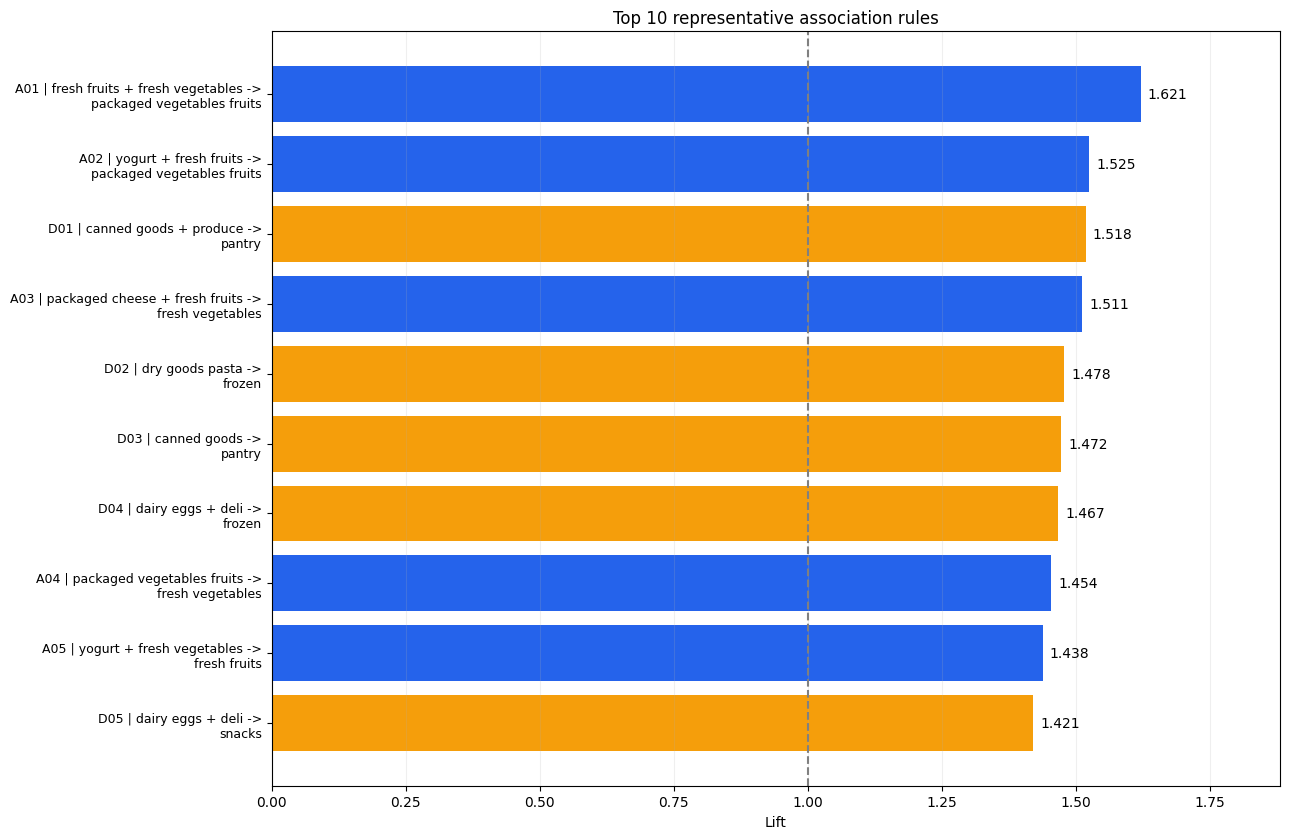

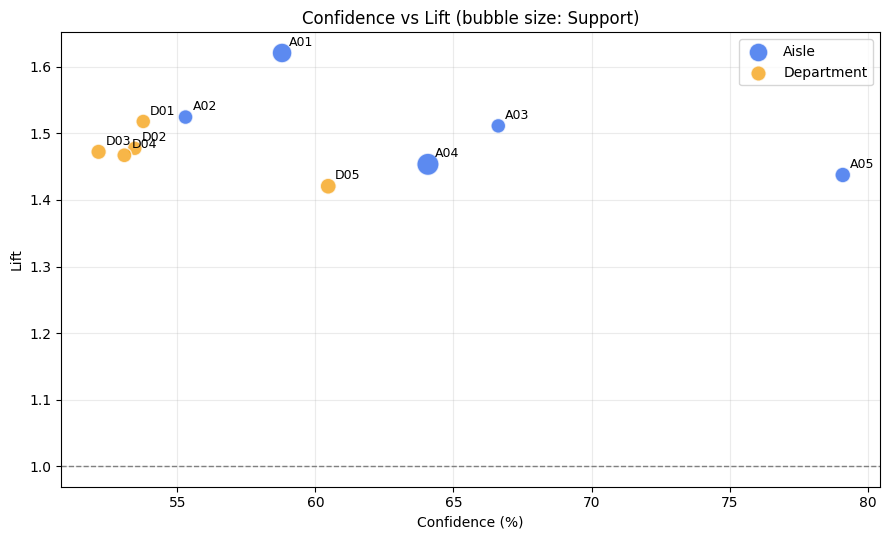

T33.3 - HAI BIEU DO: DAT


In [19]:
# T33.3 - Biểu đồ Lift và Confidence - Lift (kích thước theo Support)
colors = {"aisle":"#2563EB", "department":"#F59E0B"}
sorted_top = top10.sort_values("lift", ascending=True)
labels = [f"{r.rule_id} | {r.antecedent_names} ->\n{r.consequent_names}" for r in sorted_top.itertuples()]
fig, ax = plt.subplots(figsize=(13, 8.5))
bars = ax.barh(np.arange(len(sorted_top)), sorted_top.lift, color=[colors[x] for x in sorted_top.level])
ax.set_yticks(np.arange(len(sorted_top)), labels, fontsize=9)
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.axvline(1.0, color="gray", linestyle="--")
ax.set(xlabel="Lift", title="Top 10 representative association rules")
ax.set_xlim(0, sorted_top.lift.max()*1.16)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "T33_top10_lift.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5.5))
for level in ["aisle", "department"]:
    part = top10[top10.level == level]
    ax.scatter(part.confidence*100, part.lift, s=part.support*1100,
               label=level.capitalize(), color=colors[level], alpha=.75,
               edgecolors="white", linewidths=1)
    for r in part.itertuples():
        ax.annotate(r.rule_id, (r.confidence*100, r.lift), xytext=(5,5),
                    textcoords="offset points", fontsize=9)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Confidence (%)", ylabel="Lift",
       title="Confidence vs Lift (bubble size: Support)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "T33_confidence_lift_scatter.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("T33.3 - HAI BIEU DO: DAT")

## 6. Kiểm chứng tái lập và bàn giao
**Kiểm chứng giá trị**: số ID mẫu, số tập mục, số luật và chỉ số của 10 luật được so với các file gốc ở `Output/Step 4`. **Không đối chiếu bằng phép bằng tuyệt đối thời gian chạy**, vì kết quả thời gian phụ thuộc tài nguyên Colab. Nếu có tệp tham chiếu vắng mặt thì đánh dấu `NO_REFERENCE`; không coi đó là kết quả khớp. Ghi manifest gồm cấu hình và danh sách file được xuất để nhóm dễ chạy lại.

In [20]:
# 6.1 - Kiểm tra tái lập trên bộ kết quả B4 đã lưu trước đó
repro = []

def add_check(name, current, expected, detail=""):
    ok = bool(current == expected)
    repro.append({"check": name, "status": "PASS" if ok else "FAIL",
                  "actual": str(current), "expected": str(expected), "note": detail})

def compare_csv(reference_filename, reproduced_filename, columns, key_columns=None, numerical_tol=1e-9):
    old_path = INPUT_DIR / reference_filename
    new_path = OUTPUT_DIR / reproduced_filename
    if not old_path.is_file():
        repro.append({"check": reference_filename, "status": "NO_REFERENCE", "actual": "exists",
                      "expected": "Original CSV", "note": "Thiếu tệp tham chiếu ở Step 4"})
        return
    old, new = pd.read_csv(old_path, encoding="utf-8-sig"), pd.read_csv(new_path, encoding="utf-8-sig")
    if key_columns:
        old = old.sort_values(key_columns).reset_index(drop=True)
        new = new.sort_values(key_columns).reset_index(drop=True)
    passed = old.shape[0] == new.shape[0]
    if passed:
        for column in columns:
            if pd.api.types.is_numeric_dtype(old[column]) and pd.api.types.is_numeric_dtype(new[column]):
                passed &= bool(np.allclose(old[column], new[column], atol=numerical_tol, rtol=0))
            else:
                passed &= bool(old[column].astype(str).equals(new[column].astype(str)))
    repro.append({"check": reference_filename, "status": "PASS" if passed else "FAIL",
                  "actual": f"{len(new)} records", "expected": f"{len(old)} records",
                  "note": "Đối chiếu các cột: " + ", ".join(columns)})

add_check("T29 source transactions", len(matrix_aisle), 206657)
add_check("T30 5k support 2%", int(test_summary[(test_summary.algorithm=="Apriori") & (test_summary.min_support==0.02)].frequent_itemsets.iloc[0]), 739)
add_check("T30 5k support 5%", int(test_summary[(test_summary.algorithm=="Apriori") & (test_summary.min_support==0.05)].frequent_itemsets.iloc[0]), 157)
add_check("T30 5k support 10%", int(test_summary[(test_summary.algorithm=="Apriori") & (test_summary.min_support==0.10)].frequent_itemsets.iloc[0]), 36)
add_check("T30 10k Aisle", len(main_itemsets["aisle"]), 36)
add_check("T30 10k Department", len(main_itemsets["department"]), 93)
add_check("T31 closed Aisle", int(closed_summary.loc[closed_summary.level=="aisle", "closed_itemsets"].iloc[0]), 36)
add_check("T31 closed Department", int(closed_summary.loc[closed_summary.level=="department", "closed_itemsets"].iloc[0]), 93)
add_check("T32 all Aisle", len(all_rules["aisle"]), 56)
add_check("T32 all Department", len(all_rules["department"]), 310)
add_check("T32 filtered Aisle", len(filtered_rules["aisle"]), 26)
add_check("T32 filtered Department", len(filtered_rules["department"]), 112)
add_check("T33 top rules", len(top10), 10)

compare_csv("T30_sample_order_ids.csv", "T30_sample_order_ids.csv", ["order_id"])
compare_csv("T30_comparison.csv", "T30_comparison.csv",
            ["level", "algorithm", "transactions", "min_support", "frequent_itemsets"],
            key_columns=["level", "algorithm"])
compare_csv("T31_closed_summary.csv", "T31_closed_summary.csv",
            ["level", "frequent_itemsets", "closed_itemsets"], key_columns=["level"])
compare_csv("T32_rules_summary.csv", "T32_rules_summary.csv",
            ["level", "all_rules", "filtered_rules"], key_columns=["level"])
compare_csv("T33_top10_rules.csv", "T33_top10_rules.csv",
            ["rule_id", "level", "antecedents", "consequents", "support", "confidence", "lift"],
            key_columns=["rule_id"])
report = pd.DataFrame(repro)
report.to_csv(OUTPUT_DIR / "B4_repro_check.csv", index=False, encoding="utf-8-sig")
display(report)

metadata = {
    "source_db": str(SOURCE_DB),
    "output_dir": str(OUTPUT_DIR),
    "data_source": "Instacart prior user-sampled transactions, B3 Step3 DuckDB",
    "configuration": {"seed":SEED, "test_n":N_TEST, "main_n":N_MAIN,
        "support_grid": SUPPORT_LEVELS_TEST, "repeats":TEST_REPEATS,
        "main_min_support":MIN_SUPPORT_MAIN, "max_len":MAX_LEN,
        "min_confidence":MIN_CONFIDENCE, "min_lift_exclusive":MIN_LIFT_EXCLUSIVE},
    "output_files": sorted([str(p.relative_to(OUTPUT_DIR)) for p in OUTPUT_DIR.rglob("*") if p.is_file()]),
    "interpretation_limitations": [
        "mined itemsets restricted to length <= 3",
        "T31 closure check applies only to mined itemsets, not full CHARM implementation",
        "execution times are not deterministic",
        "association rules indicate correlation, not causation",
    ]
}
(OUTPUT_DIR / "B4_manifest.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
fail = report[report.status == "FAIL"]
if not fail.empty:
    print("CÓ SAI KHÁC KHI TÁI LẬP - kiểm tra B4_repro_check.csv")
    display(fail)
    raise AssertionError("Tái lập chưa khớp dữ liệu gốc; chưa bàn giao")
if (report.status == "NO_REFERENCE").any():
    print("B4 - DA GHI KET QUA; CO TEP CHUA CO BAN GOC DE DOI CHIEU (NO_REFERENCE)")
else:
    print("B4 - KIEM CHUNG TAI LAP: DAT")
print("Lưu ý: NO_REFERENCE nghĩa là thiếu file gốc để so sánh trực tiếp.")
print("HOAN THANH SOURCE CODE B4 - T29 DEN T33")

,check,status,actual,expected,note
0,T29 source transactions,PASS,206657,206657,
1,T30 5k support 2%,PASS,739,739,
2,T30 5k support 5%,PASS,157,157,
3,T30 5k support 10%,PASS,36,36,
4,T30 10k Aisle,PASS,36,36,
5,T30 10k Department,PASS,93,93,
6,T31 closed Aisle,PASS,36,36,
7,T31 closed Department,PASS,93,93,
8,T32 all Aisle,PASS,56,56,
9,T32 all Department,PASS,310,310,


B4 - KIEM CHUNG TAI LAP: DAT
Lưu ý: NO_REFERENCE nghĩa là thiếu file gốc để so sánh trực tiếp.
HOAN THANH SOURCE CODE B4 - T29 DEN T33
